# Early warning on OULAD

A tutor can contact about a fifth of a module. The question is who to put on that list by week 2, 4, 8 or 12, and whether the list misses students in some demographic groups.

The label is binary. **At risk** means the final result is Withdrawn or Fail. Pass and Distinction are the other class. The four-way label stays in the tables for description only.

Data: the original Open University tables (Kuzilek, Hlosta and Zdrahal, 2017, *Scientific Data*), CC BY 4.0. The Kaggle copy adds an AI-written `vle.title` column; this project does not use it. The OU CDN link currently 404s, so the loader takes the same release from the UCI repository and checks the published row counts (32,593 registrations, 10,655,280 click rows, 22 presentations).


In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "src"))

from oulad.config import CACHE_VERSION, FIG_DIR, PROC_DIR, REPORT_DIR

from oulad.features import LEAKAGE_RULES
from oulad.pipeline import get_context
import json

ctx = get_context()
exclusion = json.loads((REPORT_DIR / "exclusion.json").read_text())
print("registrations", exclusion["n_rows"])
print("distinct students", exclusion["n_students"])
print("never started (unregistered before day 0)", exclusion["n_never_started"])
print("withdrawn label but no unregistration date", exclusion["n_withdrawn_label_but_no_date"])
print("final results", exclusion["final_result_counts"])
for day in (0, 14, 28, 56, 84):
    print(
        f"day {day:>3}: eligible {exclusion[f'n_eligible_day_{day}']:,}  "
        f"already left {exclusion[f'n_already_left_day_{day}']:,}  "
        f"at-risk rate {exclusion[f'base_rate_day_{day}']:.3f}"
    )


Loading cached cohort and click totals.


registrations 32593
distinct students 28785
never started (unregistered before day 0) 2678
withdrawn label but no unregistration date 93
final results {'Distinction': 3024, 'Fail': 7052, 'Pass': 12361, 'Withdrawn': 10156}
day   0: eligible 29,496  already left 419  at-risk rate 0.478
day  14: eligible 28,119  already left 1,796  at-risk rate 0.453
day  28: eligible 27,538  already left 2,377  at-risk rate 0.441
day  56: eligible 26,522  already left 3,393  at-risk rate 0.420
day  84: eligible 25,724  already left 4,191  at-risk rate 0.402


## What is allowed into a feature

`date_unregistration` is not a predictor. It only decides who is still on the module. Students who unregistered before day 0 never started, so they are out of every model. Students who have already left by the cutoff are out of the main model too: a tutor does not need a score to know that. A sensitivity fit puts them back, to show how much that inflates accuracy.

Clicks and assessment scores are cumulative only through the cutoff. Exams are dropped. Banked scores from an earlier presentation are treated as known on day 0.


In [2]:
for rule in LEAKAGE_RULES:
    print("-", rule)
print()
print(ctx.cohort[["code_module", "code_presentation", "final_result", "imd_band", "disability", "age_band", "gender"]].head())


- Clicks after the cutoff are excluded. Totals are the cumulative sum through the last observed day at or before the cutoff.
- The last-7-day window is the seven days ending on the cutoff: dates in (cutoff-7, cutoff].
- Assessment scores count only when date_submitted is at or before the cutoff. Exam rows are excluded.
- An assessment is due only when its scheduled date is at or before the cutoff. That calendar is known in advance.
- date_unregistration is never a feature. It only decides who is still enrolled.
- Students with date_unregistration < 0 are excluded at every cutoff. They never started.
- The main model also excludes students with date_unregistration <= cutoff. A sensitivity fit keeps them.
- final_result is the label only. id_student and code_presentation are not features.
- Banked scores (is_banked = 1) are treated as known from day 0, so a late transfer date cannot hide or delay them.

  code_module code_presentation final_result imd_band disability age_band  \
0       

## What the cohort looks like

The outcome mix is not the same module to module, which is why a random split that mixes presentations looks better than a split that has to survive the next year. The click curves are restricted to students still registered in that week, so the withdrawn line is not just zeros after they leave. The first tutor-marked assignment is the first milestone a tutor actually sees.


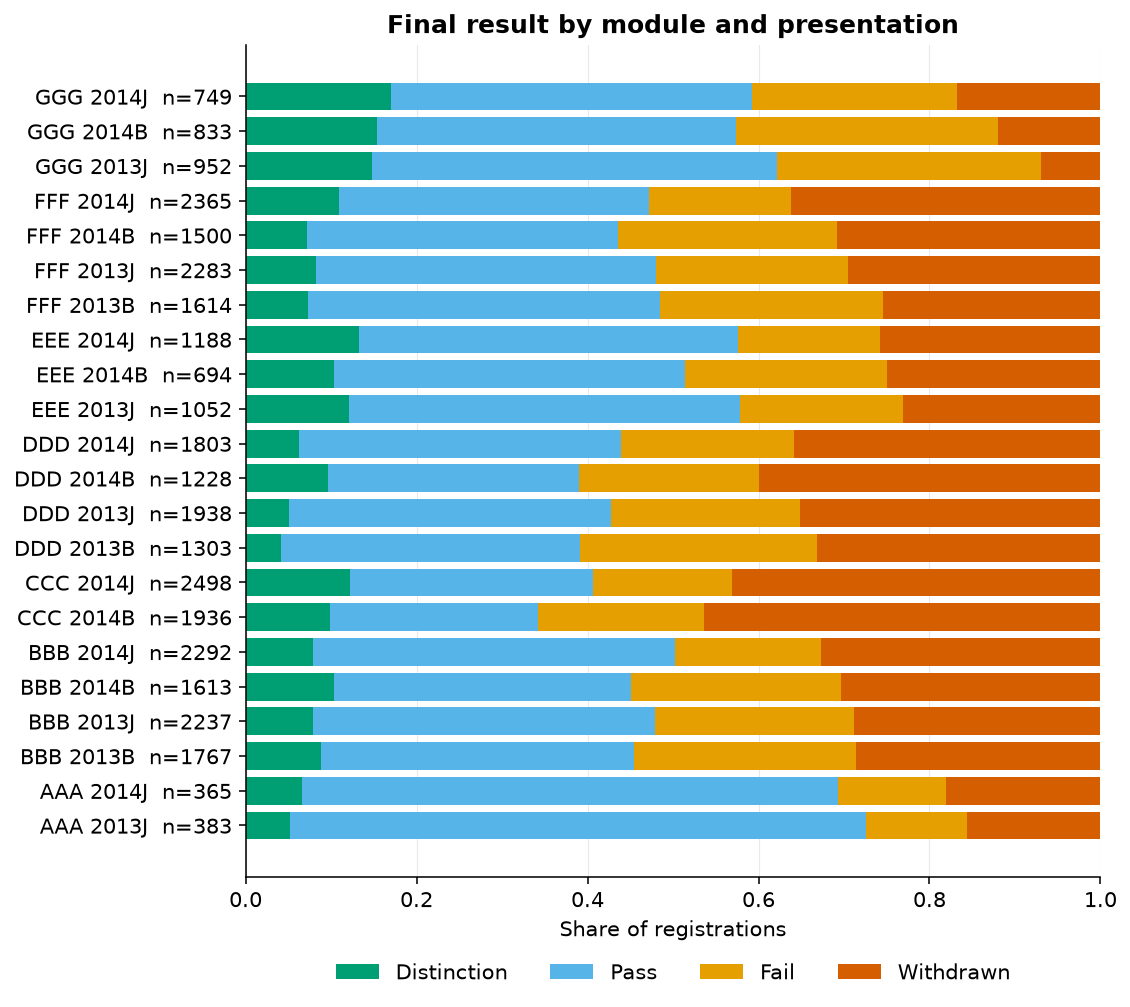

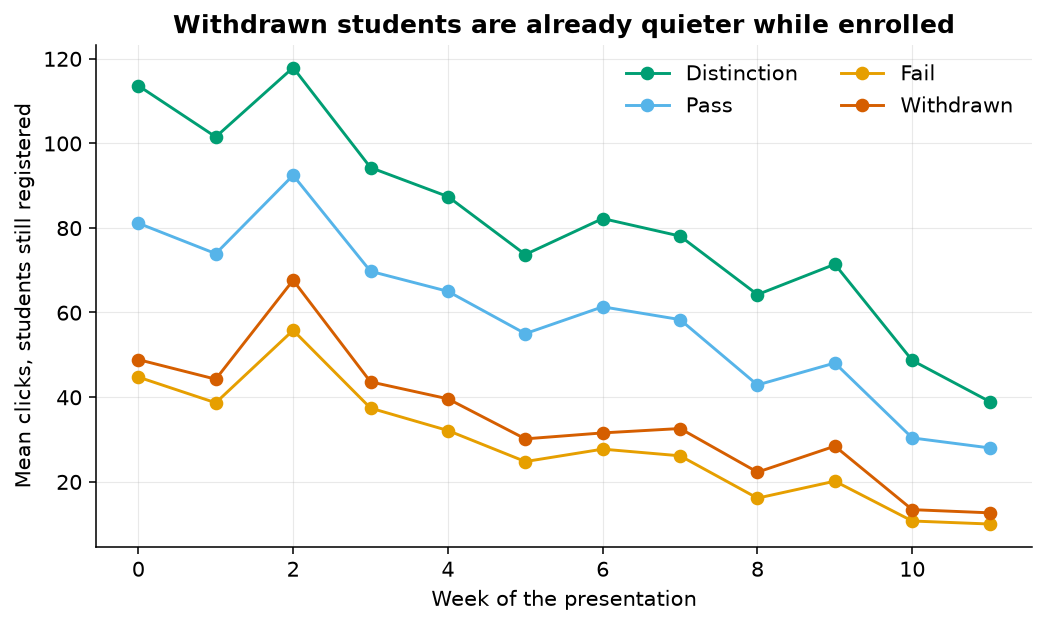

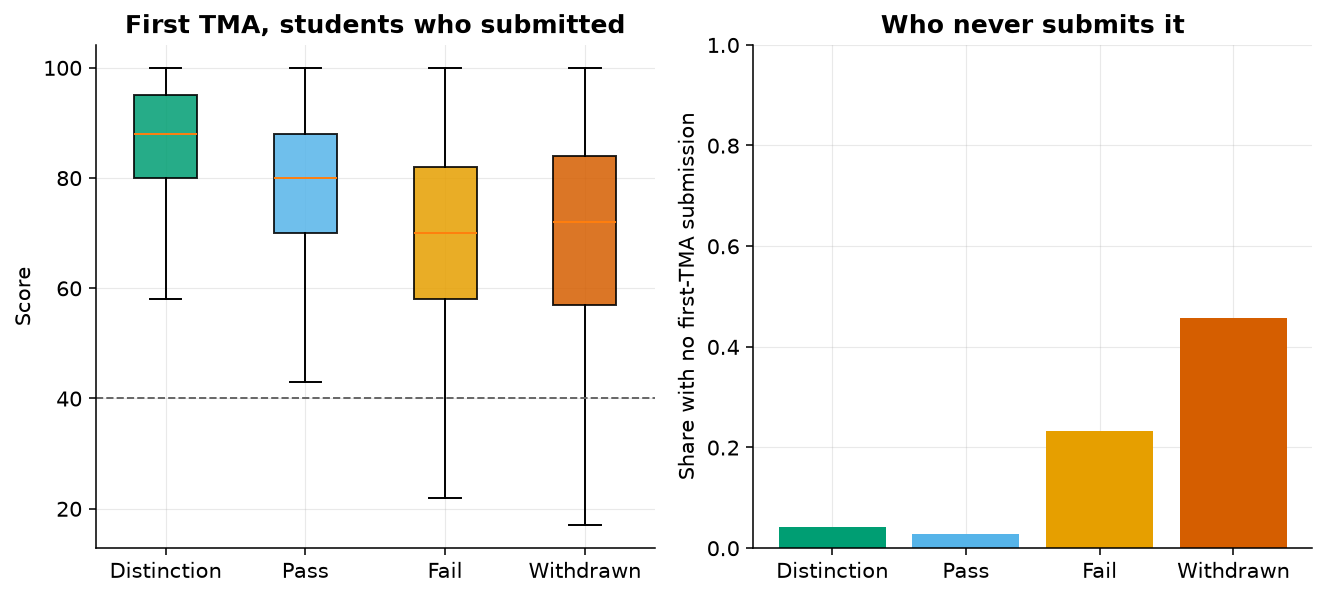

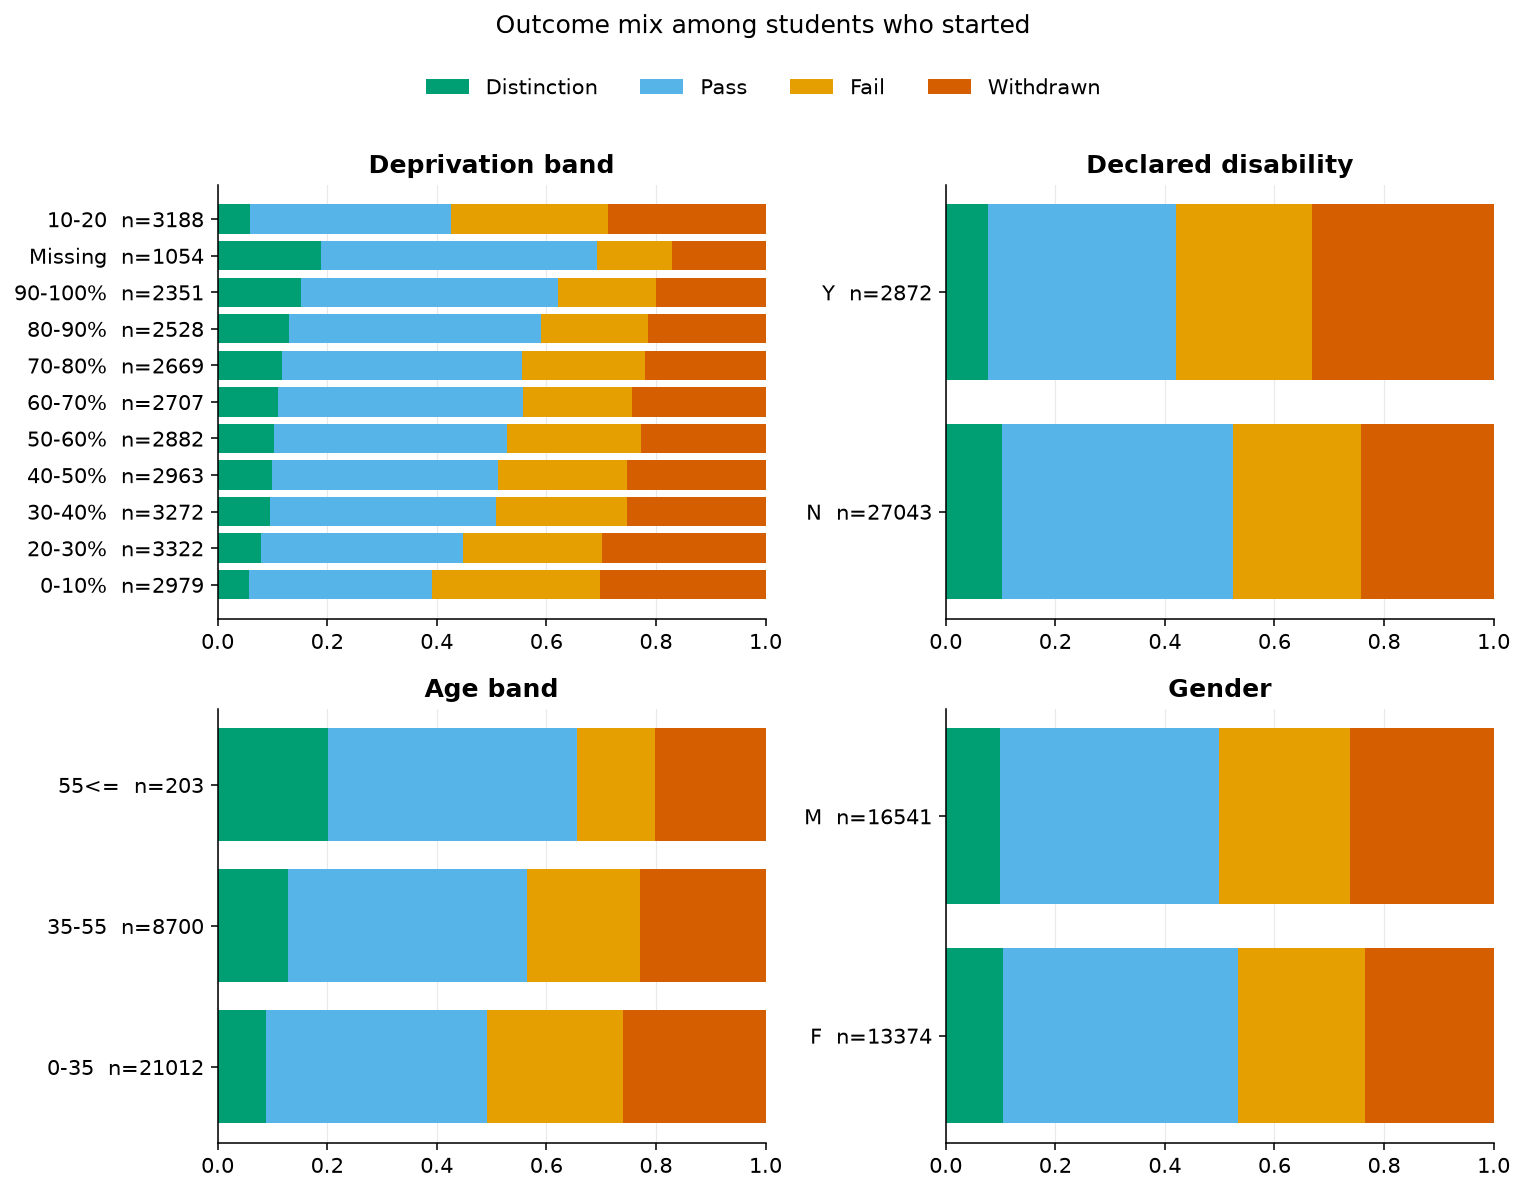

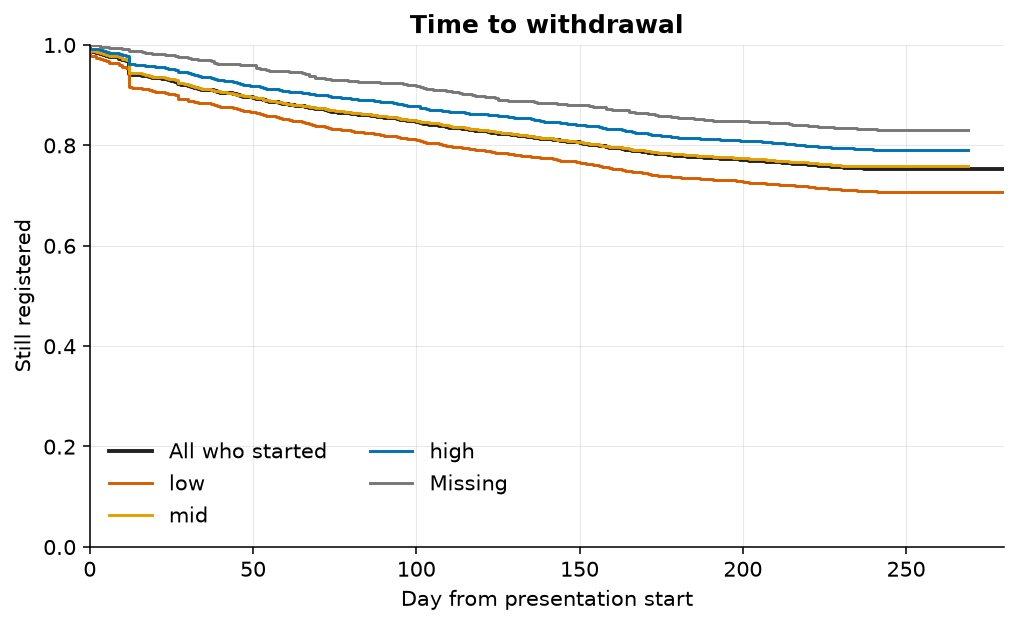

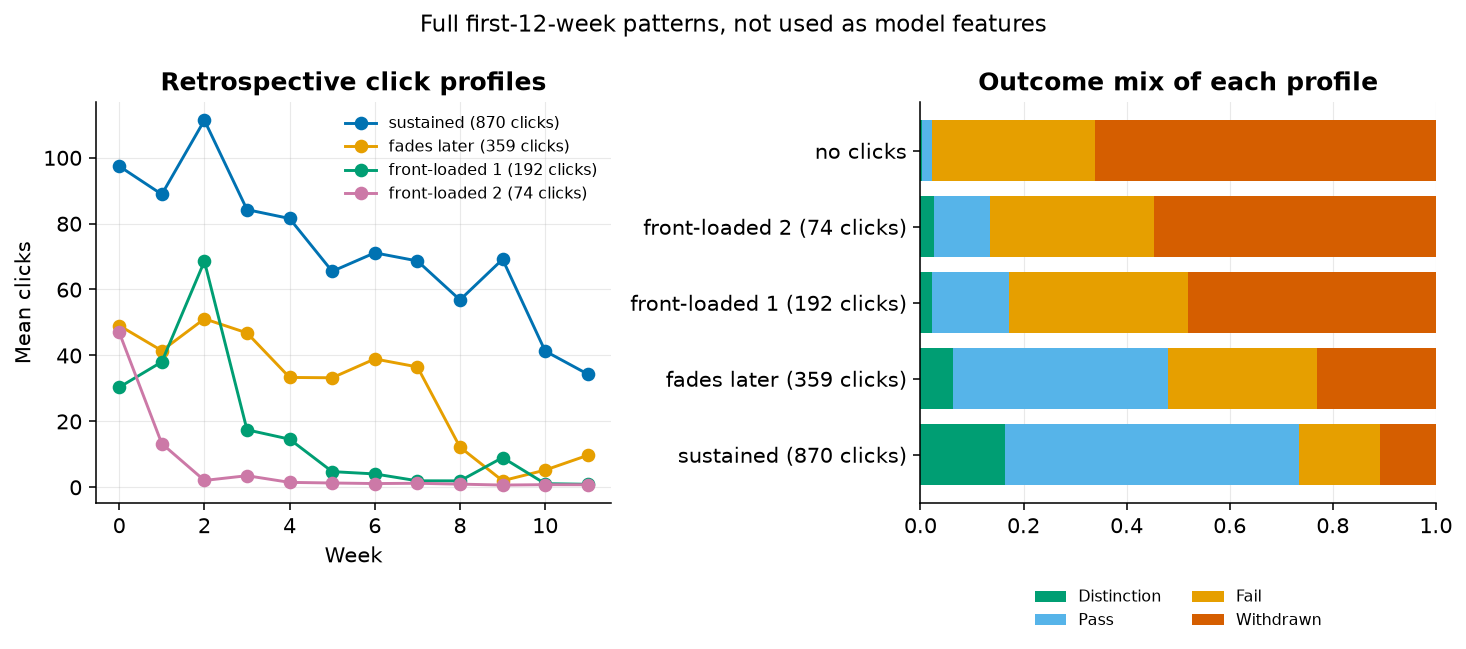

In [3]:
for name in (
    "outcome_mix",
    "weekly_clicks",
    "first_tma",
    "demographics",
    "withdrawal_km",
    "engagement_clusters",
):
    display(Image(filename=str(FIG_DIR / f"{name}.png")))


The cluster figure uses the whole first 12 weeks. It is a description of how study patterns and outcomes go together. Those full-horizon profiles are not features in the early-warning model, because at week 4 the later weeks have not happened.

The withdrawal curve is time-to-unregistration, censored at the end of the presentation for students who stay. It is not a model of failure. Students who fail are still registered; they are the censored ones.
